Homework 6, problem 2, part c

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('big12.csv')
df_played = df[df['completed'] == 1].copy()

# unique teams across home and away columns
teams = sorted(list(set(df_played['home'].unique()) | set(df_played['away'].unique())))
m = len(teams)
team_to_idx = {team: idx for idx, team in enumerate(teams)}

In [3]:
# counting total games played (n_i) and headcount wins (h_ij)
n = np.zeros(m)
h = np.zeros((m, m))

for _, row in df_played.iterrows():
    u = team_to_idx[row['home']]
    v = team_to_idx[row['away']]
    pts_u = int(row['home_pts'])
    pts_v = int(row['away_pts'])
    
    n[u] += 1
    n[v] += 1
    
    # game outcomes
    if pts_u > pts_v: # team u beat team v
        h[u, v] += 1  
    elif pts_v > pts_u: # team v beat team u
        h[v, u] += 1  
    else: # ties - split win in half
        h[u, v] += 0.5
        h[v, u] += 0.5

In [4]:
pi_uniform = np.ones((m, m)) / m

pi_distance = np.zeros((m, m))
for i in range(m):
    for j in range(m):
        if i != j:
            pi_distance[i, j] = 1.0 / (1.0 + abs(i - j))

pi_distance /= pi_distance.sum(axis=1, keepdims=True)

# 2025 season prior
h_2025 = np.zeros((m, m))
df_2025 = df_played[df_played['season'] == 2025]
for _, row in df_2025.iterrows():
    u, v = team_to_idx[row['home']], team_to_idx[row['away']]
    if row['home_pts'] > row['away_pts']:
        h_2025[u, v] += 1
    elif row['away_pts'] > row['home_pts']:
        h_2025[v, u] += 1

pi_historical = h_2025 + 0.1
pi_historical /= pi_historical.sum(axis=1, keepdims=True)

priors = {
    "Uniform Prior": pi_uniform,
    "Distance-based Prior": pi_distance,
    "2025 Season Prior": pi_historical
}

In [5]:
# power iteration
def solve_pagerank(h_mat, n_vec, pi_mat, w=0.1, tol=1e-6, max_iter=10000):
    # creating matrix A
    A = np.zeros((m, m))
    for i in range(m):
        denom = n_vec[i] + w * (m - 1)
        for j in range(m):
            if i != j:
                A[i, j] = (h_mat[i, j] + w * pi_mat[i, j]) / denom
            else:
                A[i, j] = 0.0
                
    r = np.ones(m) / m # r_0
    iterations = 0
    
    # power iteration loop
    for k in range(max_iter):
        r_next = A.T @ r
        r_next /= np.sum(r_next)
        
        # linear solve
        if np.linalg.norm(r_next - r, ord=1) < tol:
            r = r_next
            iterations = k + 1
            break
        r = r_next
        
    if iterations == 0:
        iterations = max_iter
        
    # dominant eigenvalue approximation
    lambda_est = np.mean((A @ r) / r)
    return r, iterations, lambda_est, A

In [8]:
# verifying exact iteration counts
results = {}
for name, pi_matrix in priors.items():
    r_vec, iters, lam, A_mat = solve_pagerank(h, n, pi_matrix, w=0.1)
    results[name] = r_vec
    
    # from part a
    row_sums = np.sum(A_mat, axis=1)
    print(f"\n{name} Results")
    print(f"Convergence achieved in exactly: {iters} iterations.")
    print(f"Estimated λ: {lam:.4f}")
    print(f"Row Sum Bounds Verification: Min row sum = {np.min(row_sums):.5f} <= λ <= Max row sum = {np.max(row_sums):.5f}")


Uniform Prior Results
Convergence achieved in exactly: 19 iterations.
Estimated λ: 1.6376
Row Sum Bounds Verification: Min row sum = 0.08750 <= λ <= Max row sum = 0.82176

Distance-based Prior Results
Convergence achieved in exactly: 19 iterations.
Estimated λ: 1.6082
Row Sum Bounds Verification: Min row sum = 0.08800 <= λ <= Max row sum = 0.82222

2025 Season Prior Results
Convergence achieved in exactly: 19 iterations.
Estimated λ: 1.8590
Row Sum Bounds Verification: Min row sum = 0.08769 <= λ <= Max row sum = 0.82215


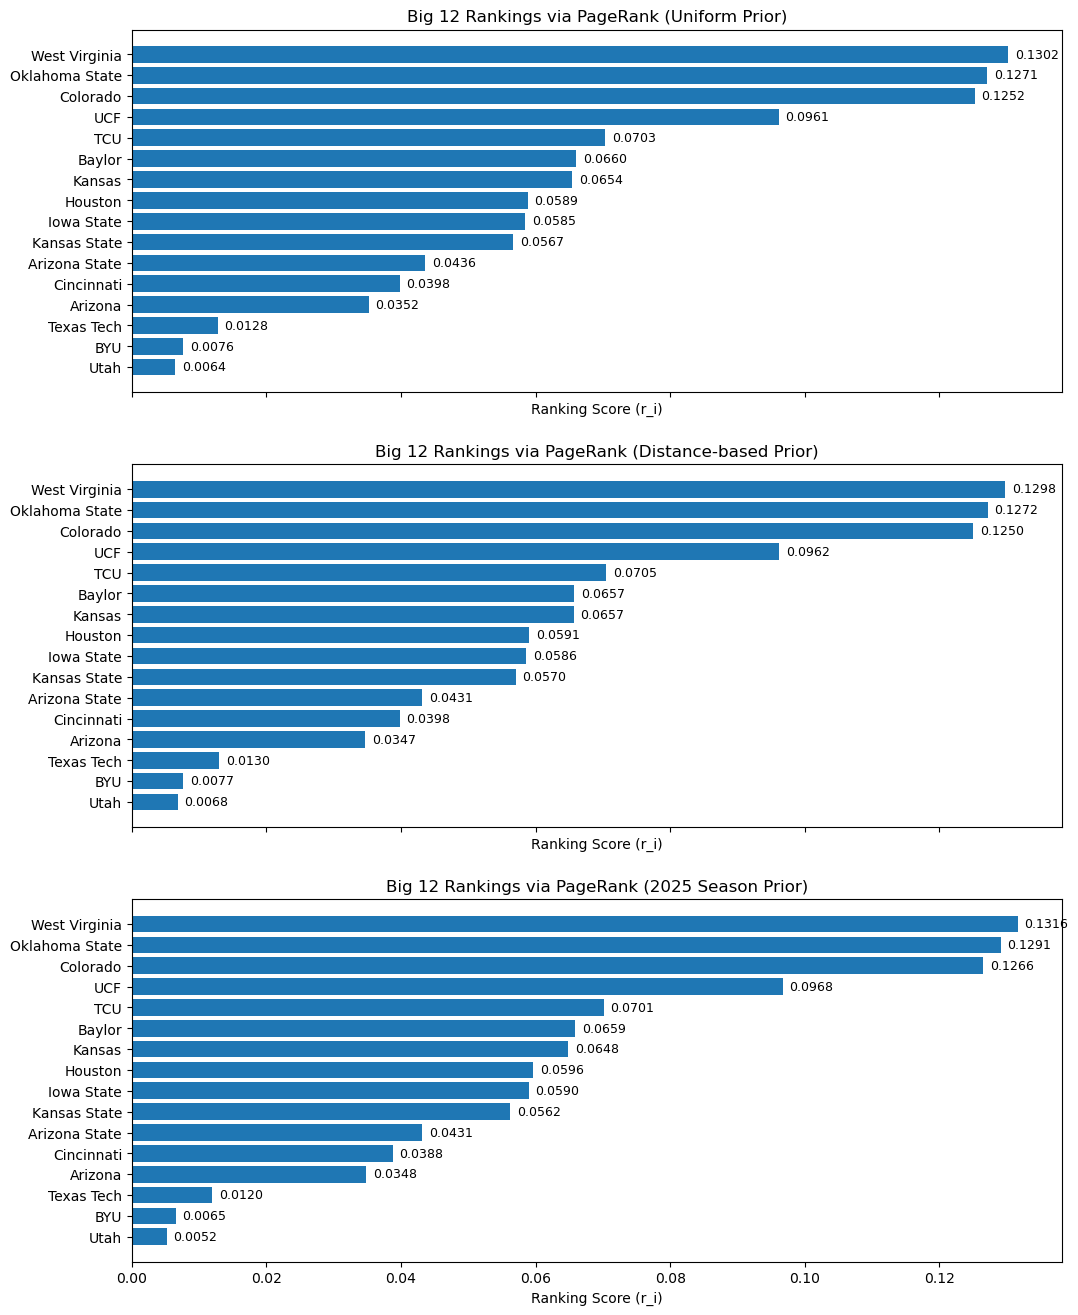

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 16), sharex=True)
y_pos = np.arange(m)

for ax, (name, r_vec) in zip(axes, results.items()):
    
    sorted_indices = np.argsort(r_vec) # sort teams by calculated ranking scores
    sorted_teams = [teams[i] for i in sorted_indices]
    sorted_scores = r_vec[sorted_indices]
    
    bars = ax.barh(y_pos, sorted_scores)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sorted_teams)
    ax.set_title(f"Big 12 Rankings via PageRank ({name})")
    ax.set_xlabel("Ranking Score (r_i)")
    
    for bar in bars: # numerical labels
        width = bar.get_width()
        ax.text(width + 0.001, bar.get_y() + bar.get_height()/2, f'{width:.4f}', 
                va='center', ha='left', fontsize=9)

plt.show()
